# 01 Exploratory data analysis

Training split only: the validation and test patients are never looked at here.
Run the pipeline first (`clean`, `split`, `features`, `prepare`). Figures are saved to `reports/figures/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from icu_forecast.config import ROOT, load_config
from icu_forecast.features import next_snapshot
from icu_forecast.prepare import load_features

cfg = load_config()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

df = load_features(cfg)
train = df[df.split == "train"].copy()
base = train.y_24h.mean()
print(f"train snapshots: {len(train):,}  patients: {train.subject_id.nunique():,}  admissions: {train.hadm_id.nunique():,}")

train snapshots: 513,555  patients: 37,525  admissions: 98,353


## Target distribution and class balance

          0     1
24h  509389  4166
48h  506519  7036 

24h    0.008112
48h    0.013701
Name: positive_rate, dtype: float64


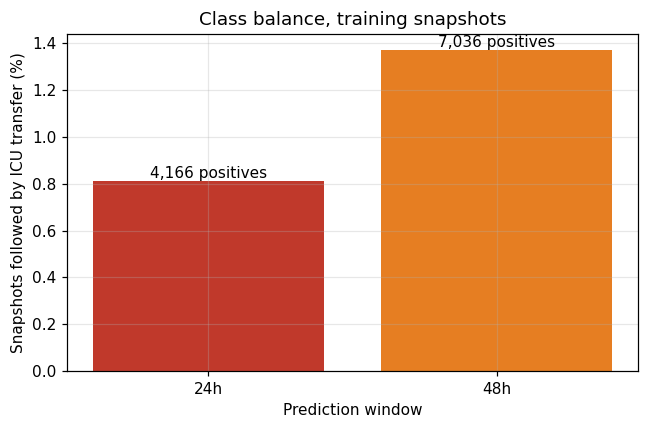

In [2]:
counts = pd.DataFrame({h: train[f"y_{h}"].value_counts() for h in ["24h", "48h"]}).T
print(counts, "\n")
print((counts[1] / counts.sum(axis=1)).rename("positive_rate"))

fig, ax = plt.subplots(figsize=(6, 4))
rates = counts[1] / counts.sum(axis=1) * 100
bars = ax.bar(rates.index, rates.values, color=["#c0392b", "#e67e22"])
for b, n in zip(bars, counts[1]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{n:,} positives", ha="center", va="bottom")
ax.set_xlabel("Prediction window")
ax.set_ylabel("Snapshots followed by ICU transfer (%)")
ax.set_title("Class balance, training snapshots")
fig.tight_layout(); fig.savefig(FIG / "fig1_class_balance.png")

## Timing of ICU transfers relative to admission

Daily 08:00 snapshots cannot see transfers that happen before the first snapshot.

train ward-to-ICU admissions: 6,261
transferred before the first snapshot: 31.3%
count    6261.0
mean       85.3
std       157.6
min         0.0
25%         6.1
50%        28.2
75%       102.1
90%       218.4
max      3825.0
Name: hours_to_icu, dtype: float64


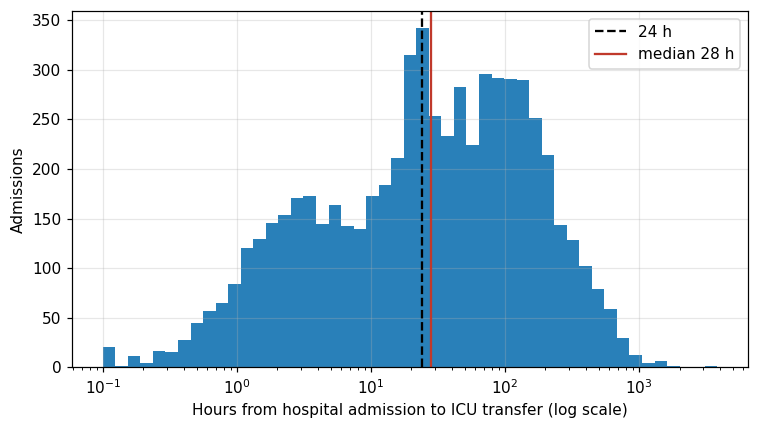

In [3]:
cohort = pd.read_parquet(cfg["paths"]["processed"] / "cohort.parquet")
split = pd.read_csv(cfg["paths"]["processed"] / "split.csv")
icu = cohort.merge(split, on="subject_id").query("split == 'train' and has_icu").copy()
icu["hours_to_icu"] = (icu.first_icu_time - icu.admittime).dt.total_seconds() / 3600
first_snap = next_snapshot(icu.admittime, cfg["snapshot"]["hour"])
icu["before_first_snapshot"] = icu.first_icu_time <= first_snap
print(f"train ward-to-ICU admissions: {len(icu):,}")
print(f"transferred before the first snapshot: {icu.before_first_snapshot.mean():.1%}")
print(icu.hours_to_icu.describe(percentiles=[.25, .5, .75, .9]).round(1))

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.logspace(-1, np.log10(icu.hours_to_icu.max() + 1), 50)
ax.hist(icu.hours_to_icu.clip(lower=0.1), bins=bins, color="#2980b9")
ax.set_xscale("log")
ax.axvline(24, color="k", ls="--", label="24 h")
ax.axvline(icu.hours_to_icu.median(), color="#c0392b", label=f"median {icu.hours_to_icu.median():.0f} h")
ax.set_xlabel("Hours from hospital admission to ICU transfer (log scale)")
ax.set_ylabel("Admissions")
ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fig2_time_to_icu.png")

## Key labs versus the target

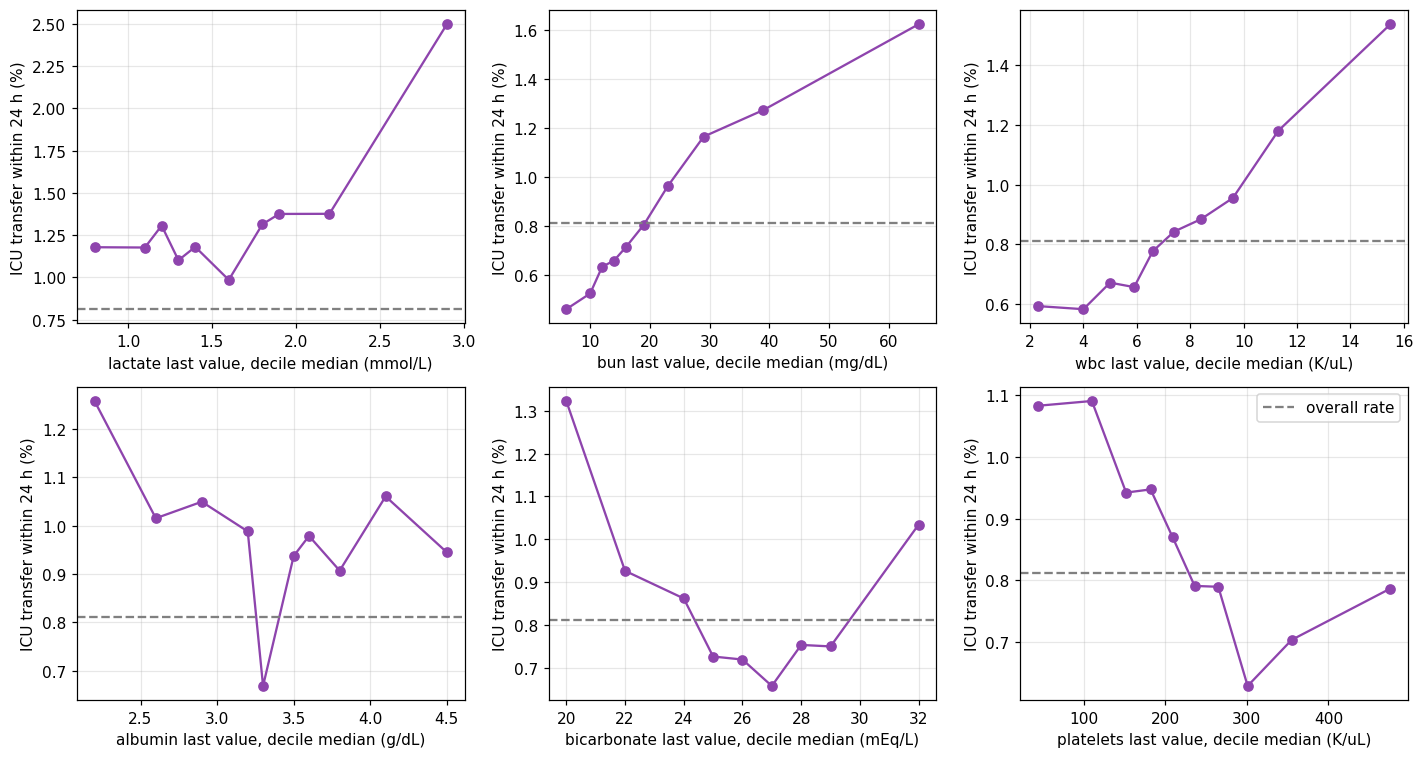

In [4]:
units = {"lactate_last": "mmol/L", "bun_last": "mg/dL", "wbc_last": "K/uL", "albumin_last": "g/dL",
         "bicarbonate_last": "mEq/L", "platelets_last": "K/uL"}
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (col, unit) in zip(axes.flat, units.items()):
    s = train[[col, "y_24h"]].dropna()
    s["bin"] = pd.qcut(s[col], 10, duplicates="drop")
    r = s.groupby("bin", observed=True).agg(x=(col, "median"), rate=("y_24h", "mean"))
    ax.plot(r.x, r.rate * 100, marker="o", color="#8e44ad")
    ax.axhline(base * 100, ls="--", color="grey", label="overall rate")
    ax.set_xlabel(f"{col.replace('_last', '')} last value, decile median ({unit})")
    ax.set_ylabel("ICU transfer within 24 h (%)")
ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fig3_labs_vs_target.png")

## Informative missingness: was the lab ordered in the last 24 h?

            share_measured  rate_if_measured  rate_if_not
lab                                                      
lactate             0.0344            0.0387       0.0070
ph                  0.0215            0.0528       0.0071
troponin_t          0.0269            0.0236       0.0077
inr                 0.2905            0.0142       0.0056
albumin             0.1358            0.0130       0.0073
magnesium           0.5676            0.0101       0.0055
creatinine          0.6203            0.0101       0.0049


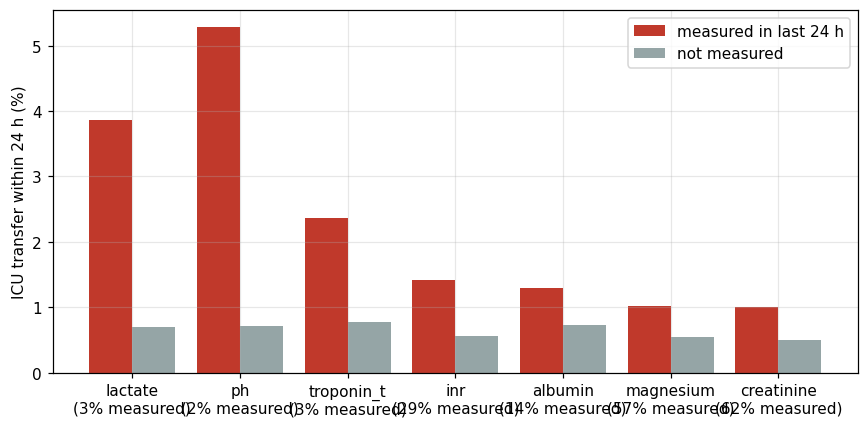

In [5]:
labs = ["lactate", "ph", "troponin_t", "inr", "albumin", "magnesium", "creatinine"]
rows = []
for lab in labs:
    measured = train[f"{lab}_count24h"] > 0
    rows.append({"lab": lab, "share_measured": measured.mean(),
                 "rate_if_measured": train.y_24h[measured].mean(), "rate_if_not": train.y_24h[~measured].mean()})
miss = pd.DataFrame(rows).set_index("lab")
print(miss.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(miss))
ax.bar(x - 0.2, miss.rate_if_measured * 100, 0.4, label="measured in last 24 h", color="#c0392b")
ax.bar(x + 0.2, miss.rate_if_not * 100, 0.4, label="not measured", color="#95a5a6")
ax.set_xticks(x, [f"{l}\n({s:.0%} measured)" for l, s in zip(miss.index, miss.share_measured)])
ax.set_ylabel("ICU transfer within 24 h (%)")
ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fig4_missingness_vs_target.png")

## Relationships among features

strongest pairs:
 bun_last          creatinine_last    0.71
chloride_last     sodium_last        0.60
albumin_last      calcium_last       0.52
bicarbonate_last  pco2_last          0.50
platelets_last    wbc_last           0.45
albumin_last      hemoglobin_last    0.40
pco2_last         ph_last           -0.37
bilirubin_last    platelets_last    -0.37
dtype: float64


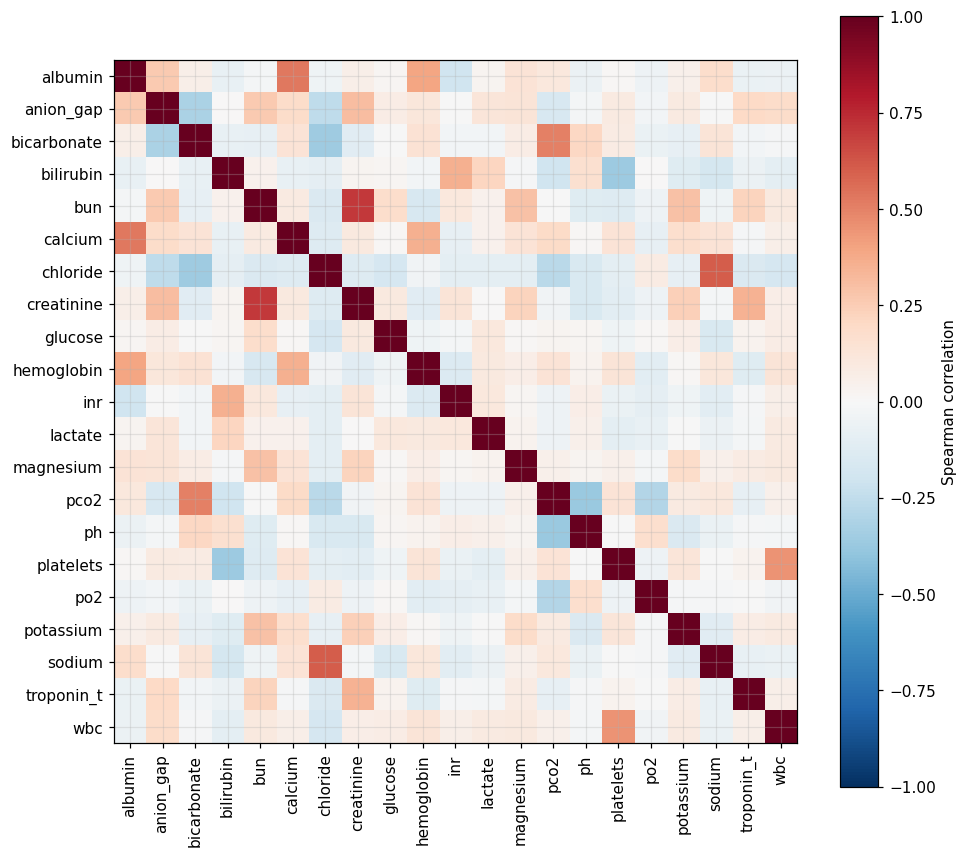

In [6]:
last_cols = [c for c in train.columns if c.endswith("_last")]
corr = train[last_cols].sample(200_000, random_state=cfg["seed"]).corr(method="spearman")
names = [c.replace("_last", "") for c in last_cols]

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=90)
ax.set_yticks(range(len(names)), names)
fig.colorbar(im, ax=ax, label="Spearman correlation")
fig.tight_layout(); fig.savefig(FIG / "fig5_lab_correlation.png")

pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
print("strongest pairs:\n", pairs.head(8).round(2))

## Group structure: ward unit and day of stay

                                        mean    size
careunit                                            
Psychiatry                            0.0000   61942
Obstetrics (Postpartum & Antepartum)  0.0012    6042
Hematology/Oncology Intermediate      0.0052   30924
Surgery                               0.0062   10401
Hematology/Oncology                   0.0070   49066
Medicine                              0.0071  136589
Med/Surg/GYN                          0.0075   11721
Surgery/Trauma                        0.0079   10712
Med/Surg/Trauma                       0.0087   10436
Med/Surg                              0.0089   34104
Vascular                              0.0091   20378
Neurology                             0.0097   18650
Transplant                            0.0122   38100
Medicine/Cardiology Intermediate      0.0135   12126
Medicine/Cardiology                   0.0185   29071


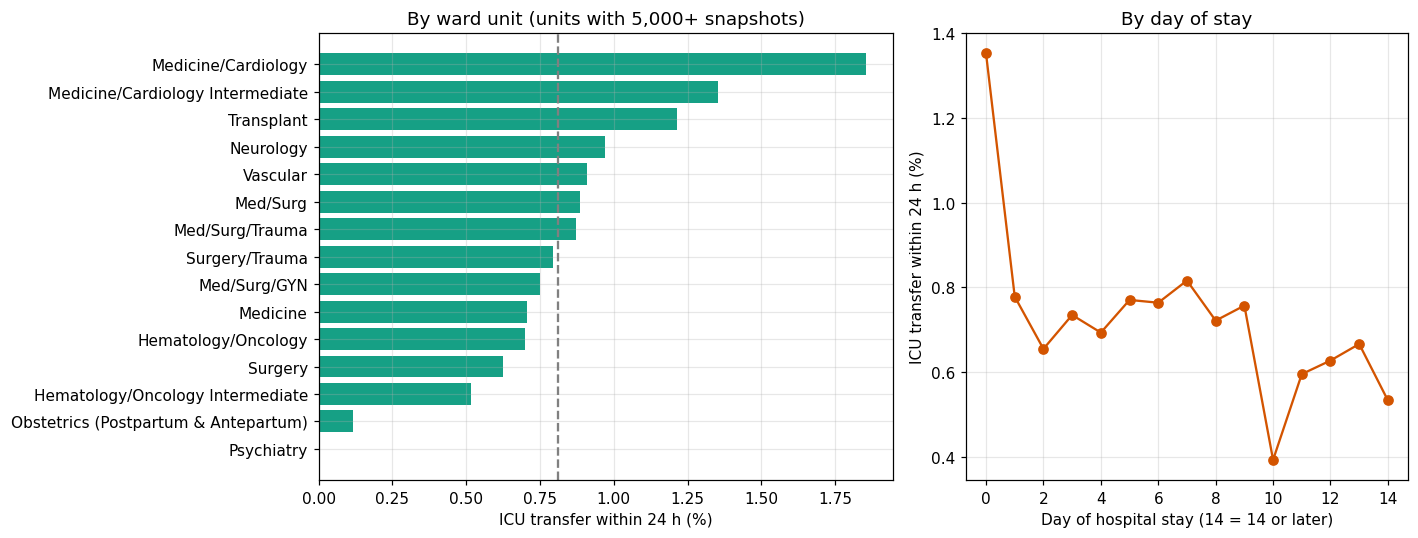

In [7]:
unit = train.groupby("careunit").y_24h.agg(["mean", "size"]).query("size >= 5000").sort_values("mean")
day = train.assign(day=(train.hours_since_admit // 24).clip(upper=14).astype(int)).groupby("day").y_24h.mean()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.3, 1]})
a1.barh(unit.index, unit["mean"] * 100, color="#16a085")
a1.axvline(base * 100, ls="--", color="grey")
a1.set_xlabel("ICU transfer within 24 h (%)")
a1.set_title("By ward unit (units with 5,000+ snapshots)")
a2.plot(day.index, day * 100, marker="o", color="#d35400")
a2.set_xlabel("Day of hospital stay (14 = 14 or later)")
a2.set_ylabel("ICU transfer within 24 h (%)")
a2.set_title("By day of stay")
fig.tight_layout(); fig.savefig(FIG / "fig6_unit_and_day.png")
print(unit.round(4))